# Customer Segmentation: K-Means and DBSCAN

**DEPI Graduation Project**

This notebook performs customer segmentation on `customer_features.csv`, compares K-Means and DBSCAN, and records every tested configuration and both final models in MLflow.

The notebook is designed for local Jupyter environments and Google Colab. It uses only the preprocessed dataset and does not unnecessarily repeat preprocessing.

## 1. Environment Setup

In [1]:
import sys
import os
import subprocess
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

# Install missing packages in both Colab and local Jupyter environments.
for package in ["pandas", "numpy", "matplotlib", "seaborn", "scikit-learn", "mlflow"]:
    try:
        __import__(package if package != "scikit-learn" else "sklearn")
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

try:
    import mlflow
    import mlflow.sklearn
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "mlflow"])
    import mlflow
    import mlflow.sklearn

os.environ["MLFLOW_ALLOW_FILE_STORE"] = "true"

print("Environment ready")
print("MLflow version:", mlflow.__version__)

2026/11/23 18:52:55 INFO mlflow.agent.hint: Load the `mlflow-trace-instrumentation` skill at C:\Users\idris\AppData\Local\Programs\Python\Python310\lib\site-packages\mlflow\assistant\skills\mlflow-trace-instrumentation\SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


Environment ready
MLflow version: 3.18.0


### Load the dataset

The loader checks common local and Colab locations. In Colab, place `customer_features.csv` in `/content` or update `DATA_PATH` below.

In [2]:
DATA_PATH = None
candidate_paths = [
    Path("customer_features.csv"),
    Path("/content/customer_features.csv"),
    Path(r"C:/Users/idris/Downloads/depi_proj_mlflow/customer_features.csv"),
]
for candidate in candidate_paths:
    if candidate.exists():
        DATA_PATH = candidate
        break

if DATA_PATH is None:
    raise FileNotFoundError(
        "customer_features.csv was not found. Put it in the notebook directory or set DATA_PATH explicitly."
    )

df = pd.read_csv(DATA_PATH)
print("Loaded from:", DATA_PATH)
print("Shape:", df.shape)
display(df.head())
print("Data types:")
display(df.dtypes.to_frame("dtype"))
display(df.describe(include="all").T)

Loaded from: customer_features.csv
Shape: (4338, 9)


,CustomerID,Recency,Frequency,Spending,Product_Diversity,Recency_scaled,Frequency_scaled,Spending_scaled,Diversity_scaled
0,12346,326,1,77183.60,1,1.461993,-0.955214,3.707716,-2.526376
1,12347,2,7,4310.00,103,-2.038734,1.074425,1.414903,0.965881
2,12348,75,4,1797.24,22,0.373104,0.386304,0.720024,-0.367738
3,12349,19,1,1757.55,73,-0.623086,-0.955214,0.702287,0.665088
4,12350,310,1,334.40,17,1.424558,-0.955214,-0.614514,-0.584387


Data types:


,dtype
CustomerID,int64
Recency,int64
Frequency,int64
Spending,float64
Product_Diversity,int64
Recency_scaled,float64
Frequency_scaled,float64
Spending_scaled,float64
Diversity_scaled,float64


,count,mean,std,min,25%,50%,75%,max
CustomerID,4338.0,1.530041e+04,1721.808492,12346.000000,13813.250000,15299.500000,16778.750000,18287.000000
Recency,4338.0,9.253642e+01,100.014169,1.000000,18.000000,51.000000,142.000000,374.000000
Frequency,4338.0,4.272015e+00,7.697998,1.000000,1.000000,2.000000,5.000000,209.000000
Spending,4338.0,2.048688e+03,8985.230220,3.750000,306.482500,668.570000,1660.597500,280206.020000
Product_Diversity,4338.0,6.150115e+01,85.366768,1.000000,16.000000,35.000000,77.000000,1787.000000
Recency_scaled,4338.0,-6.551800e-17,1.000115,-2.341296,-0.661361,0.089926,0.844792,1.564198
Frequency_scaled,4338.0,-2.948310e-17,1.000115,-0.955214,-0.955214,-0.361583,0.653237,5.858535
Spending_scaled,4338.0,-6.158692e-16,1.000115,-3.997811,-0.683580,-0.065109,0.657218,4.732381
Diversity_scaled,4338.0,7.125083e-17,1.000115,-2.526376,-0.634905,0.028243,0.711617,3.479923


### Data quality and scaling checks

In [3]:
print("Missing values:")
display(df.isna().sum().to_frame("missing_count"))

print("Duplicate rows:", int(df.duplicated().sum()))

numeric_df = df.select_dtypes(include=[np.number])
infinite_counts = np.isinf(numeric_df.to_numpy()).sum(axis=0)
infinite_table = pd.DataFrame({
    "column": numeric_df.columns,
    "infinite_count": infinite_counts,
})
display(infinite_table)

id_columns = [c for c in df.columns if "id" in c.lower()]
print("Potential customer ID columns:", id_columns)

original_feature_names = [
    c for c in ["Recency", "Frequency", "Spending", "Product_Diversity"]
    if c in df.columns
]
scaled_feature_names = [
    c for c in ["Recency_scaled", "Frequency_scaled", "Spending_scaled", "Diversity_scaled"]
    if c in df.columns
]

print("Original customer features:", original_feature_names)
print("Pre-scaled features:", scaled_feature_names)

# Prefer the supplied standardized columns. These are already scaled, so no
# additional scaler is applied unless standardized columns are unavailable.
if len(scaled_feature_names) >= 2:
    feature_names = scaled_feature_names
else:
    from sklearn.preprocessing import StandardScaler
    feature_names = original_feature_names
    feature_matrix_temp = df[feature_names].replace([np.inf, -np.inf], np.nan).dropna()
    feature_matrix = StandardScaler().fit_transform(feature_matrix_temp)
    print("Applied StandardScaler because standardized feature columns were unavailable.")

if len(scaled_feature_names) >= 2:
    feature_matrix = df[feature_names].replace([np.inf, -np.inf], np.nan).dropna().to_numpy()
    scaled_check = df[feature_names].agg(["mean", "std"]).T
    print("Scaling check for supplied standardized features:")
    display(scaled_check)

clean_index = df[feature_names].replace([np.inf, -np.inf], np.nan).dropna().index
df_clean = df.loc[clean_index].copy()
feature_matrix = df_clean[feature_names].to_numpy(dtype=float)

print("Final clustering feature matrix shape:", feature_matrix.shape)
print("Features used:", feature_names)

Missing values:


,missing_count
CustomerID,0
Recency,0
Frequency,0
Spending,0
Product_Diversity,0
Recency_scaled,0
Frequency_scaled,0
Spending_scaled,0
Diversity_scaled,0


Duplicate rows: 0


,column,infinite_count
0,CustomerID,0
1,Recency,0
2,Frequency,0
3,Spending,0
4,Product_Diversity,0
5,Recency_scaled,0
6,Frequency_scaled,0
7,Spending_scaled,0
8,Diversity_scaled,0


Potential customer ID columns: ['CustomerID']
Original customer features: ['Recency', 'Frequency', 'Spending', 'Product_Diversity']
Pre-scaled features: ['Recency_scaled', 'Frequency_scaled', 'Spending_scaled', 'Diversity_scaled']
Scaling check for supplied standardized features:


,mean,std
Recency_scaled,-6.551800e-17,1.000115
Frequency_scaled,-2.948310e-17,1.000115
Spending_scaled,-6.158692e-16,1.000115
Diversity_scaled,7.125083e-17,1.000115


Final clustering feature matrix shape: (4338, 4)
Features used: ['Recency_scaled', 'Frequency_scaled', 'Spending_scaled', 'Diversity_scaled']


### Interpretation of scaling

The scaled columns have near-zero means and unit-like standard deviations. K-Means and DBSCAN are both distance-based, so using the pre-scaled feature columns prevents Recency, Frequency, Spending, and Product Diversity from contributing according to their raw units.

## 2. K-Means Experimentation

In [4]:
k_values = list(range(2, 11))
kmeans_results = []

mlflow_tracking_dir = Path("./mlruns").resolve()
mlflow_tracking_dir.mkdir(parents=True, exist_ok=True)
mlflow.set_tracking_uri(mlflow_tracking_dir.as_uri())
mlflow.set_experiment("Customer_Segmentation_Clustering")

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(feature_matrix)
    inertia = model.inertia_
    sil = silhouette_score(feature_matrix, labels)
    db = davies_bouldin_score(feature_matrix, labels)
    ch = calinski_harabasz_score(feature_matrix, labels)

    kmeans_results.append({
        "K": k,
        "Inertia": inertia,
        "Silhouette": sil,
        "Davies_Bouldin": db,
        "Calinski_Harabasz": ch,
    })

    with mlflow.start_run(run_name=f"KMeans_K{k}") as run:
        mlflow.log_params({
            "algorithm": "KMeans",
            "n_clusters": k,
            "random_state": 42,
            "n_init": 10,
        })
        mlflow.log_metrics({
            "inertia": inertia,
            "silhouette_score": sil,
            "davies_bouldin_score": db,
            "calinski_harabasz_score": ch,
        })
        try:
            mlflow.sklearn.log_model(model, artifact_path="model")
        except Exception as exc:
            print(f"Model logging warning for K={k}: {exc}")

kmeans_results_df = pd.DataFrame(kmeans_results)
display(kmeans_results_df)

2026/11/23 18:52:57 INFO mlflow.tracking.fluent: Experiment with name 'Customer_Segmentation_Clustering' does not exist. Creating a new experiment.


2026/11/23 18:53:05 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Model logging warning for K=2: No module named 'skops'


2026/11/23 18:53:07 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Model logging warning for K=3: No module named 'skops'


2026/11/23 18:53:08 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


... (10 outputs left out)

Model logging warning for K=9: No module named 'skops'


2026/11/23 18:53:19 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Model logging warning for K=10: No module named 'skops'


,K,Inertia,Silhouette,Davies_Bouldin,Calinski_Harabasz
0,2,9128.760714,0.400320,0.952185,3905.895790
1,3,7090.399570,0.297058,1.138231,3136.929147
2,4,6148.053560,0.283686,1.200669,2632.733852
3,5,5306.885742,0.250676,1.188559,2458.700155
4,6,4818.521952,0.236703,1.242455,2253.621562
5,7,4421.681166,0.231047,1.190883,2110.860144
6,8,4113.086073,0.225793,1.184888,1991.020713
7,9,3864.658708,0.232728,1.162527,1888.484948
8,10,3651.684114,0.225528,1.189678,1804.189376


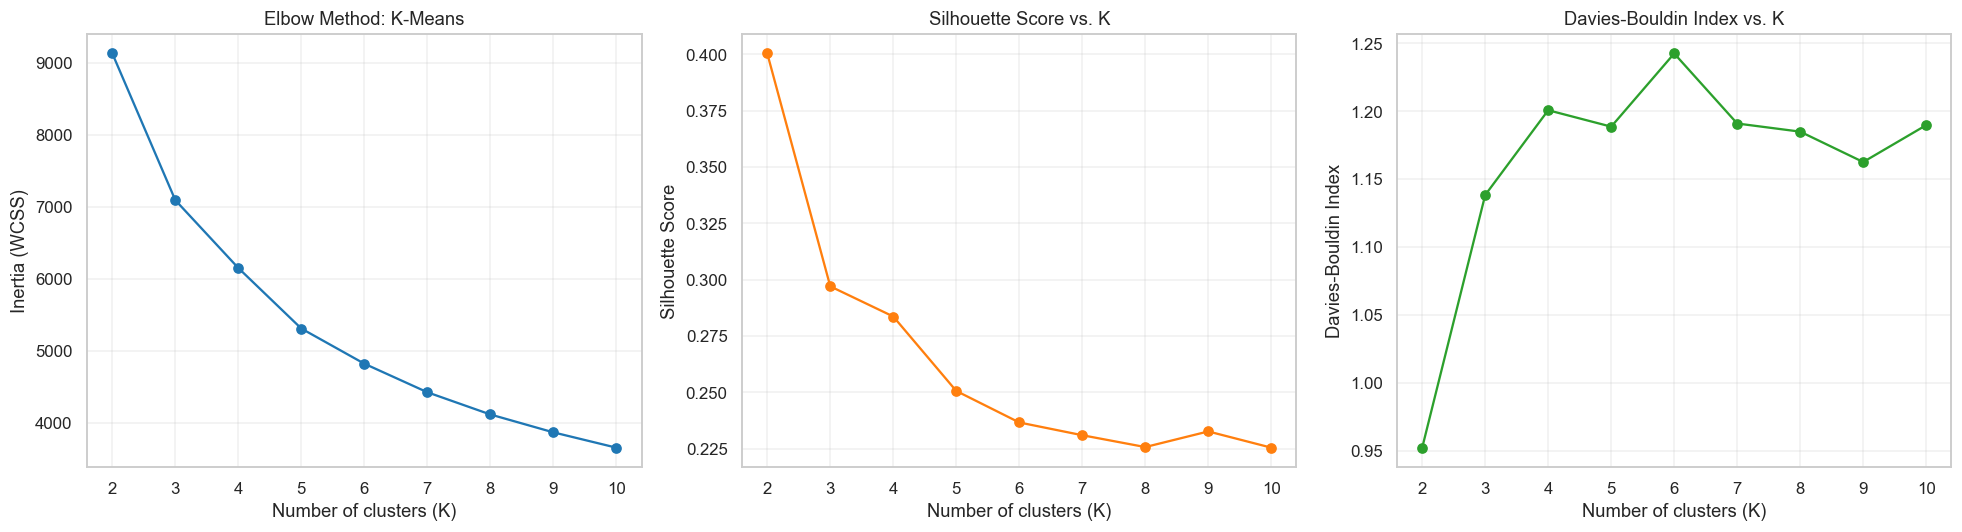

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(kmeans_results_df["K"], kmeans_results_df["Inertia"], marker="o", color="tab:blue")
axes[0].set(title="Elbow Method: K-Means", xlabel="Number of clusters (K)", ylabel="Inertia (WCSS)")

axes[1].plot(kmeans_results_df["K"], kmeans_results_df["Silhouette"], marker="o", color="tab:orange")
axes[1].set(title="Silhouette Score vs. K", xlabel="Number of clusters (K)", ylabel="Silhouette Score")

axes[2].plot(kmeans_results_df["K"], kmeans_results_df["Davies_Bouldin"], marker="o", color="tab:green")
axes[2].set(title="Davies-Bouldin Index vs. K", xlabel="Number of clusters (K)", ylabel="Davies-Bouldin Index")

for ax in axes:
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plot_path = Path("./kmeans_evaluation.png")
plt.savefig(plot_path, dpi=160, bbox_inches="tight")
plt.show()

with mlflow.start_run(run_name="KMeans_Evaluation_Artifacts"):
    mlflow.log_artifact(str(plot_path))
    mlflow.log_table(data=kmeans_results_df, artifact_file="kmeans_results.json")

### K-Means model selection

- **Elbow method:** WCSS decreases as K increases. The useful K is near the point where adding another cluster gives a diminishing reduction in inertia.
- **Silhouette score:** Higher is better. It measures separation and cohesion, but should not be the sole selection rule.
- **Davies-Bouldin index:** Lower is better. It measures average similarity between clusters.

The final K is selected from the combined plots and exported metrics below rather than from Silhouette alone.

In [6]:
# Combined evidence: elbow curvature, silhouette, and Davies-Bouldin.
ks = kmeans_results_df["K"].to_numpy(dtype=float)
inertias = kmeans_results_df["Inertia"].to_numpy(dtype=float)
p1 = np.array([ks.min(), inertias.min()])
p2 = np.array([ks.max(), inertias.max()])
line = p2 - p1
distances = []
for k, inertia in zip(ks, inertias):
    point = np.array([k, inertia])
    # Normalize x and y before computing elbow distance so units do not dominate.
    normalized_point = np.array([
        (k - ks.min()) / (ks.max() - ks.min()),
        (inertia - inertias.min()) / (inertias.max() - inertias.min()),
    ])
    normalized_p1 = np.array([0.0, 0.0])
    normalized_p2 = np.array([1.0, 1.0])
    numerator = abs(
        (normalized_p2[1] - normalized_p1[1]) * normalized_point[0]
        - (normalized_p2[0] - normalized_p1[0]) * normalized_point[1]
        + normalized_p2[0] * normalized_p1[1]
        - normalized_p2[1] * normalized_p1[0]
    )
    denominator = np.sqrt(
        (normalized_p2[1] - normalized_p1[1]) ** 2
        + (normalized_p2[0] - normalized_p1[0]) ** 2
    )
    distances.append(numerator / denominator)

candidate_elbow = int(kmeans_results_df.iloc[int(np.argmax(distances))]["K"])
silhouette_peak = int(kmeans_results_df.loc[
    kmeans_results_df["Silhouette"].idxmax(), "K"
])
db_lowest = int(kmeans_results_df.loc[
    kmeans_results_df["Davies_Bouldin"].idxmin(), "K"
])

print("Normalized elbow candidate:", candidate_elbow)
print("Highest-Silhouette candidate:", silhouette_peak)
print("Lowest-Davies-Bouldin candidate:", db_lowest)

# Prefer the elbow candidate when it agrees with at least one of the other metrics.
if candidate_elbow in (silhouette_peak, db_lowest):
    selected_k = candidate_elbow
else:
    selected_k = db_lowest

print("Selected K:", selected_k)

final_kmeans = KMeans(n_clusters=selected_k, random_state=42, n_init=10)
kmeans_labels = final_kmeans.fit_predict(feature_matrix)
df_kmeans = df_clean.copy()
df_kmeans["KMeans_Cluster"] = kmeans_labels

kmeans_silhouette = silhouette_score(feature_matrix, kmeans_labels)
kmeans_dav = davies_bouldin_score(feature_matrix, kmeans_labels)
kmeans_ch = calinski_harabasz_score(feature_matrix, kmeans_labels)
print("Final K-Means Silhouette:", kmeans_silhouette)
print("Final K-Means Davies-Bouldin:", kmeans_dav)
print("Final K-Means Calinski-Harabasz:", kmeans_ch)

Normalized elbow candidate: 2
Highest-Silhouette candidate: 2
Lowest-Davies-Bouldin candidate: 2
Selected K: 2


Final K-Means Silhouette: 0.4003195582743596
Final K-Means Davies-Bouldin: 0.9521846627211816
Final K-Means Calinski-Harabasz: 3905.8957901874246


## 3. DBSCAN Experimentation

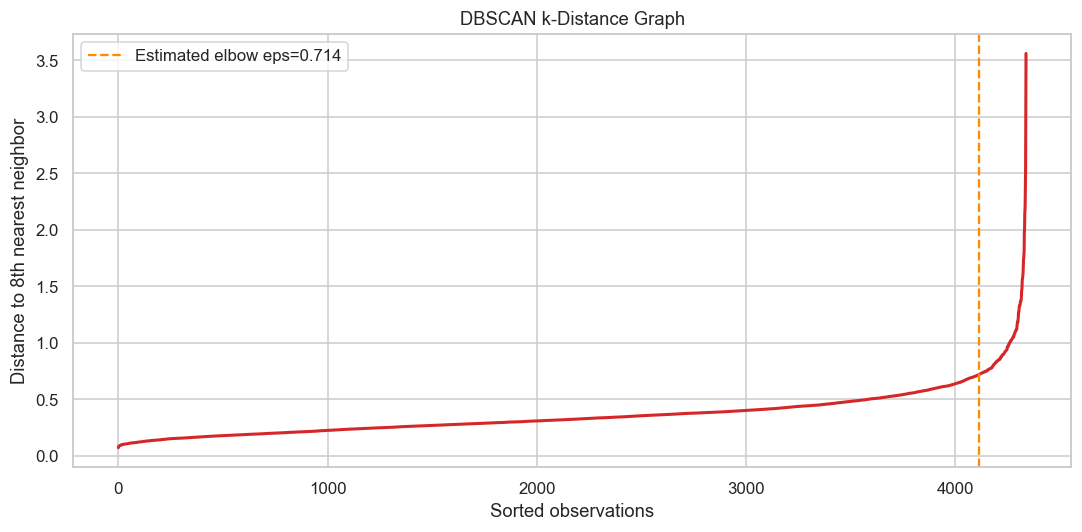

Estimated eps from k-distance elbow: 0.7137582134468473
Tested min_samples: [4, 8, 12]


Tested eps candidates: [0.5353, 0.6424, 0.7138, 0.7851, 0.8922]


2026/11/23 18:53:29 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Model logging warning for eps=0.5353, min_samples=4: No module named 'skops'


2026/11/23 18:53:30 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Model logging warning for eps=0.6424, min_samples=4: No module named 'skops'


... (23 outputs left out)

Model logging warning for eps=0.7851, min_samples=12: No module named 'skops'


2026/11/23 18:53:45 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Model logging warning for eps=0.8922, min_samples=12: No module named 'skops'


,eps,min_samples,n_clusters,n_noise_points,noise_percentage,silhouette,davies_bouldin
4,0.8922,4,1,36,0.829876,NaN,NaN
9,0.8922,8,1,47,1.083449,NaN,NaN
3,0.7851,4,1,53,1.221761,NaN,NaN
14,0.8922,12,1,61,1.406178,NaN,NaN
8,0.7851,8,1,73,1.682803,NaN,NaN
2,0.7138,4,1,74,1.705855,NaN,NaN
13,0.7851,12,1,96,2.213001,NaN,NaN
1,0.6424,4,1,103,2.374366,NaN,NaN
7,0.7138,8,1,111,2.558783,NaN,NaN
12,0.7138,12,1,127,2.927616,NaN,NaN


In [7]:
n_features = feature_matrix.shape[1]
min_samples_values = sorted(set([n_features, 2 * n_features, 3 * n_features]))

# k-distance graph uses 2 * n_features as the representative first estimate.
reference_min_samples = 2 * n_features
neighbors = NearestNeighbors(n_neighbors=reference_min_samples)
neighbors.fit(feature_matrix)
distances, _ = neighbors.kneighbors(feature_matrix)
k_distances = np.sort(distances[:, -1])

points = np.column_stack([
    np.linspace(0.0, 1.0, len(k_distances)),
    (k_distances - k_distances.min()) / (k_distances.max() - k_distances.min()),
])
line_vector = points[-1] - points[0]
line_norm = np.linalg.norm(line_vector)
perpendicular_distances = np.abs(
    line_vector[0] * (points[:, 1] - points[0, 1])
    - line_vector[1] * (points[:, 0] - points[0, 0])
) / line_norm
elbow_index = int(np.argmax(perpendicular_distances))
estimated_eps = float(k_distances[elbow_index])

plt.figure(figsize=(10, 5))
plt.plot(k_distances, color="tab:red", lw=2)
plt.axvline(elbow_index, color="darkorange", linestyle="--",
            label=f"Estimated elbow eps={estimated_eps:.3f}")
plt.title("DBSCAN k-Distance Graph")
plt.xlabel("Sorted observations")
plt.ylabel(f"Distance to {reference_min_samples}th nearest neighbor")
plt.legend()
plt.tight_layout()
kdistance_path = Path("./dbscan_k_distance.png")
plt.savefig(kdistance_path, dpi=160, bbox_inches="tight")
plt.show()

print("Estimated eps from k-distance elbow:", estimated_eps)
print("Tested min_samples:", min_samples_values)

with mlflow.start_run(run_name="DBSCAN_k_Distance_Artifact"):
    mlflow.log_params({
        "algorithm": "DBSCAN",
        "method": "k_distance_elbow",
        "k_neighbors": reference_min_samples,
        "estimated_eps": estimated_eps,
    })
    mlflow.log_artifact(str(kdistance_path))

eps_candidates = sorted(set([
    round(estimated_eps * factor, 4)
    for factor in [0.75, 0.90, 1.00, 1.10, 1.25]
]))
print("Tested eps candidates:", eps_candidates)

dbscan_results = []

for min_samples in min_samples_values:
    for eps in eps_candidates:
        model = DBSCAN(eps=eps, min_samples=min_samples, metric="euclidean")
        labels = model.fit_predict(feature_matrix)

        unique_labels = set(labels)
        n_noise = int(np.sum(labels == -1))
        n_clusters = int(len(unique_labels - {-1}))
        noise_percentage = 100.0 * n_noise / len(labels)

        valid_mask = labels != -1
        valid_labels = labels[valid_mask]
        valid_features = feature_matrix[valid_mask]
        n_valid_clusters = len(np.unique(valid_labels))

        sil = np.nan
        db = np.nan
        if n_valid_clusters >= 2 and len(valid_features) > n_valid_clusters:
            sil = silhouette_score(valid_features, valid_labels)
            db = davies_bouldin_score(valid_features, valid_labels)

        dbscan_results.append({
            "eps": eps,
            "min_samples": min_samples,
            "n_clusters": n_clusters,
            "n_noise_points": n_noise,
            "noise_percentage": noise_percentage,
            "silhouette": sil,
            "davies_bouldin": db,
        })

        with mlflow.start_run(run_name=f"DBSCAN_eps{eps:.4f}_min{min_samples}") as run:
            mlflow.log_params({
                "algorithm": "DBSCAN",
                "eps": eps,
                "min_samples": min_samples,
                "metric": "euclidean",
            })
            metrics = {
                "n_clusters": n_clusters,
                "n_noise_points": n_noise,
                "noise_percentage": noise_percentage,
            }
            if np.isfinite(sil):
                metrics["silhouette_score"] = float(sil)
            if np.isfinite(db):
                metrics["davies_bouldin_score"] = float(db)
            mlflow.log_metrics(metrics)
            try:
                mlflow.sklearn.log_model(model, artifact_path="model")
            except Exception as exc:
                print(f"Model logging warning for eps={eps}, min_samples={min_samples}: {exc}")

dbscan_results_df = pd.DataFrame(dbscan_results)
display(dbscan_results_df.sort_values(
    ["noise_percentage", "silhouette"], ascending=[True, False]
).head(20))

In [8]:
valid_dbscan = dbscan_results_df[
    (dbscan_results_df["n_clusters"] >= 2)
    & dbscan_results_df["silhouette"].notna()
    & dbscan_results_df["davies_bouldin"].notna()
].copy()

if valid_dbscan.empty:
    raise RuntimeError("No DBSCAN configuration produced at least two valid clusters.")

# Favor low noise and strong quality, while never using invalid/NaN metrics.
valid_dbscan["quality_rank"] = (
    valid_dbscan["silhouette"].rank(ascending=False)
    + valid_dbscan["davies_bouldin"].rank(ascending=True)
)
valid_dbscan["noise_rank"] = valid_dbscan["noise_percentage"].rank(ascending=True)
valid_dbscan["selection_score"] = (
    0.55 * valid_dbscan["quality_rank"]
    + 0.45 * valid_dbscan["noise_rank"]
)
selected_dbscan_row = valid_dbscan.loc[valid_dbscan["selection_score"].idxmin()]
selected_eps = float(selected_dbscan_row["eps"])
selected_min_samples = int(selected_dbscan_row["min_samples"])

print("Selected eps:", selected_eps)
print("Selected min_samples:", selected_min_samples)
print("Selected configuration:")
display(selected_dbscan_row.to_frame("value"))

final_dbscan = DBSCAN(
    eps=selected_eps,
    min_samples=selected_min_samples,
    metric="euclidean",
)
dbscan_labels = final_dbscan.fit_predict(feature_matrix)
df_dbscan = df_clean.copy()
df_dbscan["DBSCAN_Cluster"] = dbscan_labels

n_dbscan_clusters = len(set(dbscan_labels) - {-1})
n_dbscan_noise = int(np.sum(dbscan_labels == -1))
dbscan_noise_percentage = 100.0 * n_dbscan_noise / len(dbscan_labels)

noise_mask = dbscan_labels == -1
valid_mask = ~noise_mask
dbscan_silhouette = np.nan
dbscan_davies = np.nan
if len(np.unique(dbscan_labels[valid_mask])) >= 2:
    dbscan_silhouette = silhouette_score(
        feature_matrix[valid_mask], dbscan_labels[valid_mask]
    )
    dbscan_davies = davies_bouldin_score(
        feature_matrix[valid_mask], dbscan_labels[valid_mask]
    )

print("Number of DBSCAN clusters:", n_dbscan_clusters)
print("Number of noise points:", n_dbscan_noise)
print("Noise percentage:", dbscan_noise_percentage)
print("Silhouette (noise excluded):", dbscan_silhouette)
print("Davies-Bouldin (noise excluded):", dbscan_davies)

Selected eps: 0.5353
Selected min_samples: 8
Selected configuration:


,value
eps,0.535300
min_samples,8.000000
n_clusters,4.000000
n_noise_points,300.000000
noise_percentage,6.915629
silhouette,0.166164
davies_bouldin,0.896495
quality_rank,3.000000
noise_rank,2.000000
selection_score,2.550000


Number of DBSCAN clusters: 4
Number of noise points: 300
Noise percentage: 6.915629322268327
Silhouette (noise excluded): 0.16616353921593566
Davies-Bouldin (noise excluded): 0.8964947792375664


## 4. K-Means vs. DBSCAN Comparison

In [9]:
kmeans_cluster_sizes = df_kmeans["KMeans_Cluster"].value_counts().sort_index()
dbscan_cluster_sizes = df_dbscan["DBSCAN_Cluster"].value_counts().sort_index()

comparison = pd.DataFrame({
    "Metric": [
        "Number of clusters",
        "Number of noise points",
        "Silhouette Score",
        "Davies-Bouldin Index",
        "Cluster size distribution",
    ],
    "K-Means": [
        selected_k,
        0,
        round(kmeans_silhouette, 4),
        round(kmeans_dav, 4),
        kmeans_cluster_sizes.to_dict(),
    ],
    "DBSCAN": [
        n_dbscan_clusters,
        n_dbscan_noise,
        round(dbscan_silhouette, 4) if np.isfinite(dbscan_silhouette) else "Not valid",
        round(dbscan_davies, 4) if np.isfinite(dbscan_davies) else "Not valid",
        dbscan_cluster_sizes.to_dict(),
    ],
})
display(comparison)

,Metric,K-Means,DBSCAN
0,Number of clusters,2,4
1,Number of noise points,0,300
2,Silhouette Score,0.4003,0.1662
3,Davies-Bouldin Index,0.9522,0.8965
4,Cluster size distribution,"{0: 2588, 1: 1750}","{-1: 300, 0: 2591, 1: 1432, 2: 8, 3: 7}"


### Algorithm discussion

K-Means is centroid-based and assigns every observation to exactly one cluster. It is efficient and tends to create compact, roughly spherical segments, but it is sensitive to scaling and to the assumed number of clusters.

DBSCAN is density-based and can detect irregularly shaped clusters. It also labels sparse observations as noise (`-1`) instead of forcing them into a cluster. It is sensitive to `eps`, `min_samples`, and scaling.

The more suitable algorithm should be decided from the actual cluster count, silhouette and Davies-Bouldin scores, noise percentage, and interpretability of the resulting profiles below.

## 5. Customer Cluster Profiling

In [10]:
def profile_clusters(data, label_column, feature_columns):
    valid = data[data[label_column] != -1].copy() if label_column == "DBSCAN_Cluster" else data.copy()
    counts = valid[label_column].value_counts().sort_index()
    percentages = (100 * counts / len(valid)).round(2)
    means = valid.groupby(label_column)[feature_columns].mean().round(3)
    profile = pd.DataFrame({
        "Customer_Count": counts,
        "Customer_Percentage": percentages,
    }).join(means)
    return counts, profile

kmeans_counts, kmeans_profile = profile_clusters(
    df_kmeans, "KMeans_Cluster", original_feature_names
)
print("K-Means cluster sizes:")
display(kmeans_counts.to_frame("Customer_Count"))
print("K-Means feature profile:")
display(kmeans_profile)

dbscan_counts, dbscan_profile = profile_clusters(
    df_dbscan, "DBSCAN_Cluster", original_feature_names
)
print("DBSCAN normal-cluster sizes:")
display(dbscan_counts.to_frame("Customer_Count"))
print("DBSCAN feature profile:")
display(dbscan_profile)

noise_profile = df_dbscan[df_dbscan["DBSCAN_Cluster"] == -1][original_feature_names].mean().round(3)
print("DBSCAN noise point count:", int((df_dbscan["DBSCAN_Cluster"] == -1).sum()))
print("DBSCAN noise mean feature values:")
display(noise_profile.to_frame("mean"))

K-Means cluster sizes:


,Customer_Count
KMeans_Cluster,
0,2588
1,1750


K-Means feature profile:


,Customer_Count,Customer_Percentage,Recency,Frequency,Spending,Product_Diversity
KMeans_Cluster,,,,,,
0,2588,59.66,134.787,1.642,515.933,25.444
1,1750,40.34,30.054,8.161,4315.414,114.824


DBSCAN normal-cluster sizes:


,Customer_Count
DBSCAN_Cluster,
0,2591
1,1432
2,8
3,7


DBSCAN feature profile:


,Customer_Count,Customer_Percentage,Recency,Frequency,Spending,Product_Diversity
DBSCAN_Cluster,,,,,,
0,2591,64.17,59.563,4.948,1734.198,78.956
1,1432,35.46,160.615,1.000,333.166,21.293
2,8,0.20,204.750,2.125,688.250,1.250
3,7,0.17,3.000,1.000,229.833,16.286


DBSCAN noise point count: 300
DBSCAN noise mean feature values:


,mean
Recency,51.450
Frequency,14.187
Spending,13032.315
Product_Diversity,105.340


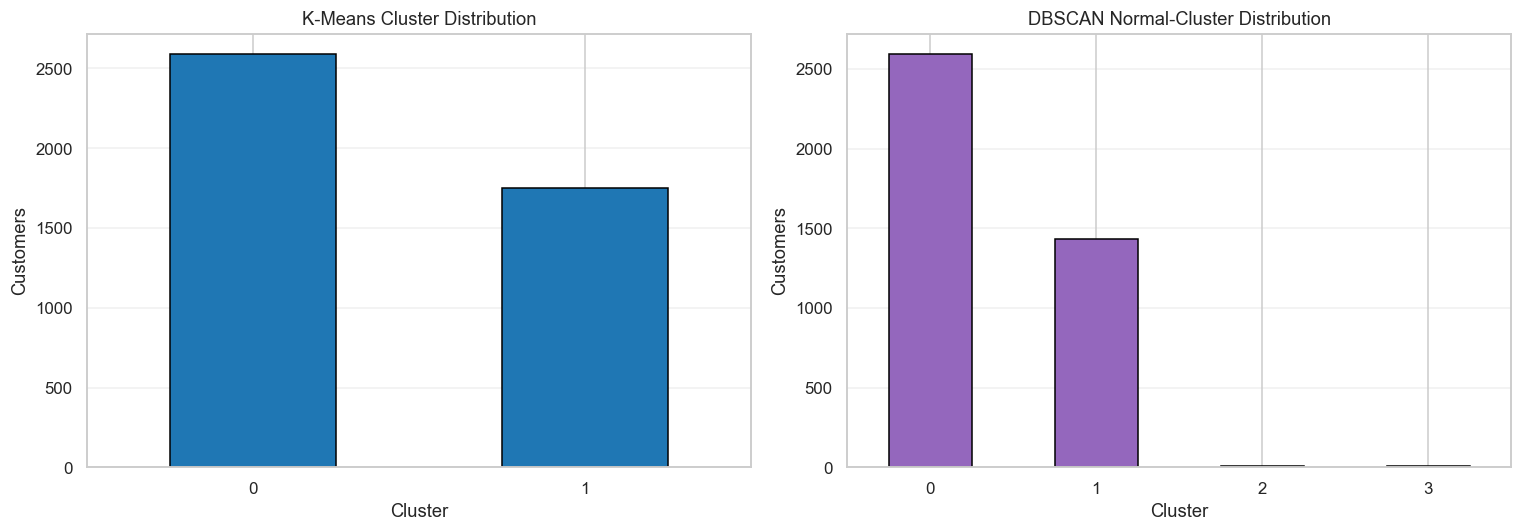

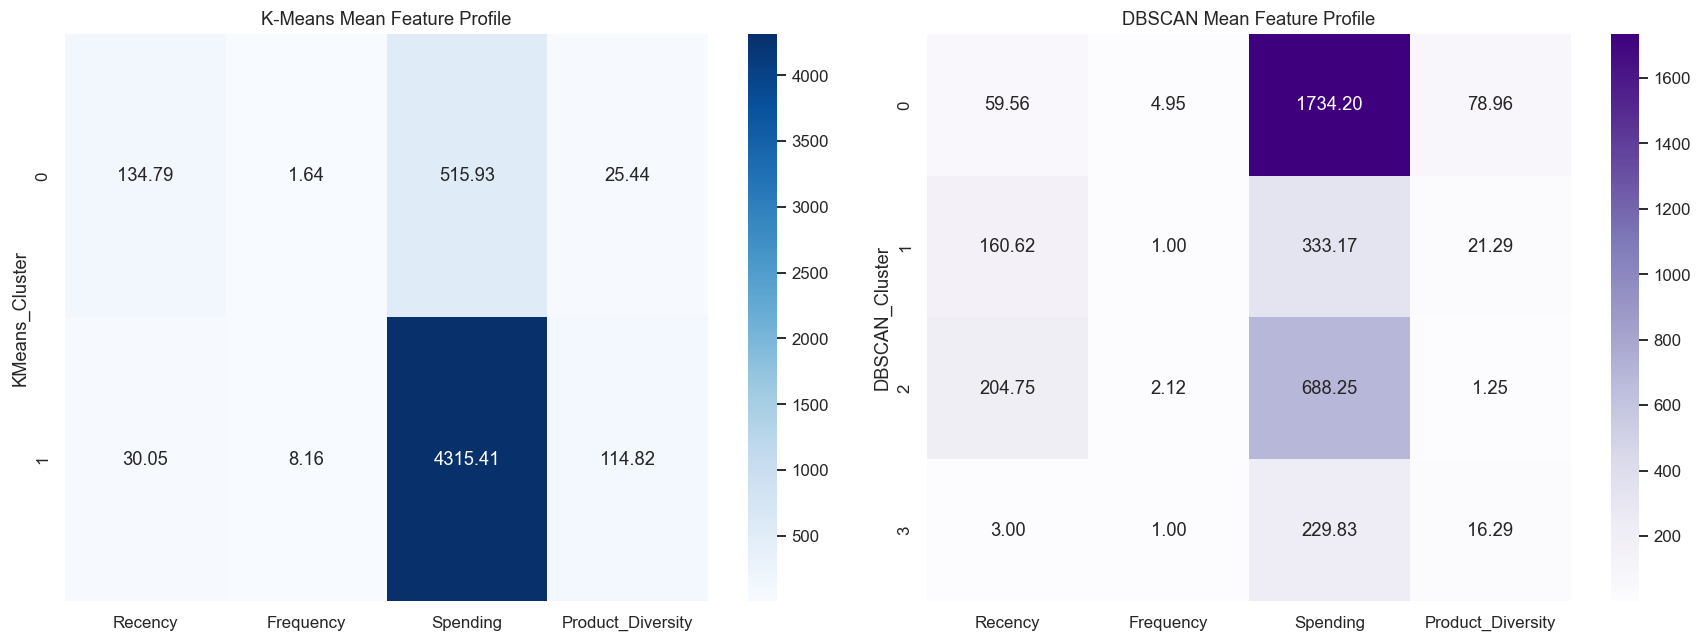

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

kmeans_counts.plot(kind="bar", ax=axes[0], color="tab:blue", edgecolor="black")
axes[0].set(title="K-Means Cluster Distribution", xlabel="Cluster", ylabel="Customers")

dbscan_counts.plot(kind="bar", ax=axes[1], color="tab:purple", edgecolor="black")
axes[1].set(title="DBSCAN Normal-Cluster Distribution", xlabel="Cluster", ylabel="Customers")

for ax in axes:
    ax.tick_params(axis="x", rotation=0)
    ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

kmeans_heatmap = kmeans_profile.drop(columns=["Customer_Count", "Customer_Percentage"])
if not kmeans_heatmap.empty:
    sns.heatmap(kmeans_heatmap, annot=True, fmt=".2f", cmap="Blues", ax=axes[0])
axes[0].set_title("K-Means Mean Feature Profile")

dbscan_heatmap = dbscan_profile.drop(columns=["Customer_Count", "Customer_Percentage"])
if not dbscan_heatmap.empty:
    sns.heatmap(dbscan_heatmap, annot=True, fmt=".2f", cmap="Purples", ax=axes[1])
axes[1].set_title("DBSCAN Mean Feature Profile")
plt.tight_layout()
plt.show()

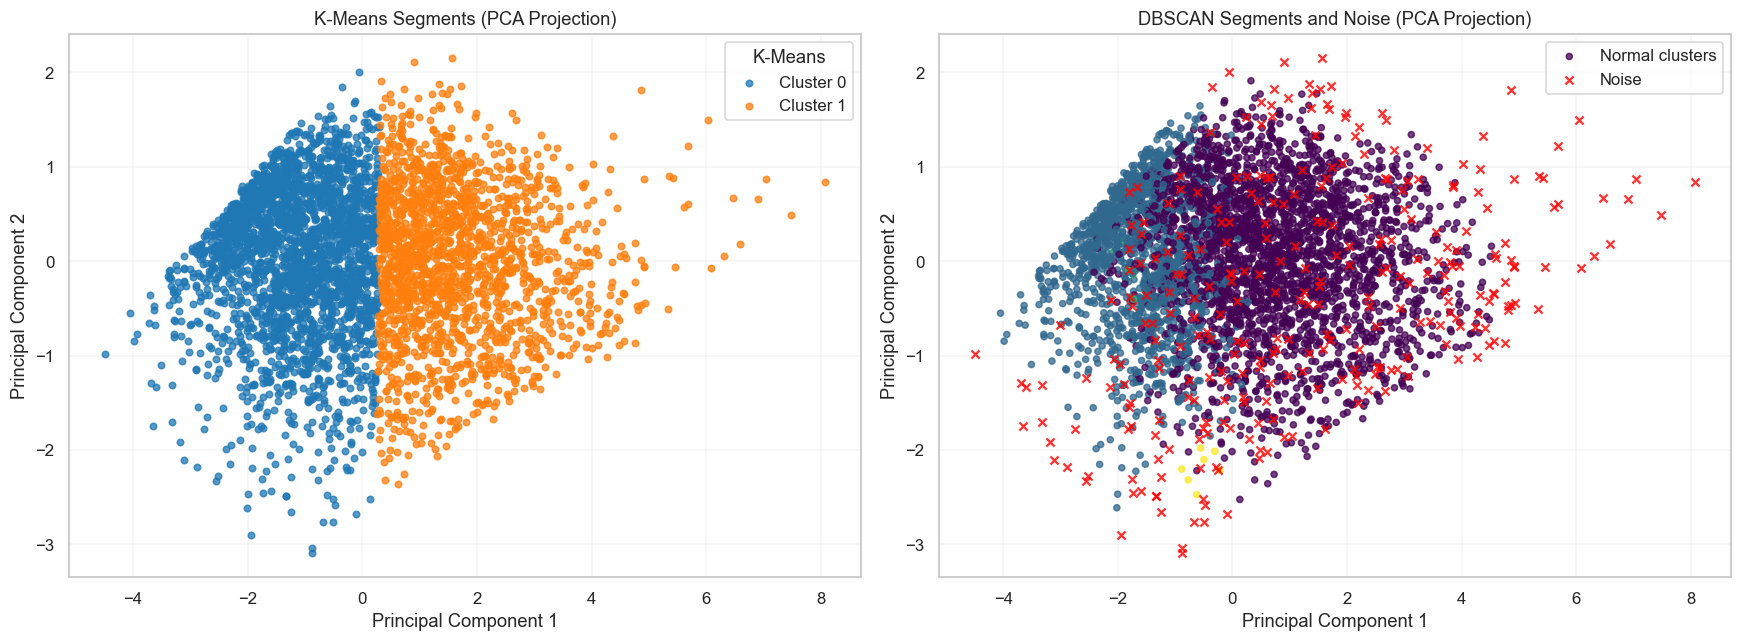

In [12]:
pca = PCA(n_components=2, random_state=42)
pca_coordinates = pca.fit_transform(feature_matrix)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

palette = sns.color_palette("tab10", n_colors=selected_k)
for cluster in sorted(np.unique(kmeans_labels)):
    mask = kmeans_labels == cluster
    axes[0].scatter(
        pca_coordinates[mask, 0], pca_coordinates[mask, 1],
        s=18, alpha=0.75, label=f"Cluster {cluster}",
        color=palette[cluster]
    )
axes[0].set_title("K-Means Segments (PCA Projection)")
axes[0].set_xlabel("Principal Component 1")
axes[0].set_ylabel("Principal Component 2")
axes[0].legend(title="K-Means")
axes[0].grid(True, alpha=0.2)

normal_mask = dbscan_labels != -1
noise_mask = dbscan_labels == -1
axes[1].scatter(
    pca_coordinates[normal_mask, 0], pca_coordinates[normal_mask, 1],
    c=dbscan_labels[normal_mask], cmap="viridis", s=16, alpha=0.75,
    label="Normal clusters"
)
axes[1].scatter(
    pca_coordinates[noise_mask, 0], pca_coordinates[noise_mask, 1],
    c="red", marker="x", s=28, alpha=0.8, label="Noise"
)
axes[1].set_title("DBSCAN Segments and Noise (PCA Projection)")
axes[1].set_xlabel("Principal Component 1")
axes[1].set_ylabel("Principal Component 2")
axes[1].legend()
axes[1].grid(True, alpha=0.2)

plt.tight_layout()
comparison_pca_path = Path("./cluster_pca_comparison.png")
plt.savefig(comparison_pca_path, dpi=160, bbox_inches="tight")
plt.show()

with mlflow.start_run(run_name="Cluster_Profiling_Artifacts"):
    mlflow.log_artifact(str(comparison_pca_path))
    mlflow.log_table(data=kmeans_profile.reset_index(), artifact_file="kmeans_cluster_profile.json")
    mlflow.log_table(data=dbscan_profile.reset_index(), artifact_file="dbscan_cluster_profile.json")

### Business interpretation

The names below must be assigned only after inspecting the actual profile tables. Use Recency, Frequency, Spending, and Product_Diversity to describe real behavior:

- Low Recency and high Frequency/Spending suggest newer or more active/high-value customers.
- High Recency usually indicates inactivity.
- High Frequency and Spending indicate loyalty and commercial value.
- High Product_Diversity may indicate broad category engagement.

Do not apply a name such as "High-Value Loyal" unless those characteristics are supported by the generated mean table.

## 6. Final MLflow Models and Artifacts

In [13]:
# Dedicated final K-Means run
with mlflow.start_run(run_name="Final_KMeans_Model") as final_km_run:
    mlflow.log_params({
        "algorithm": "KMeans",
        "n_clusters": selected_k,
        "random_state": 42,
        "n_init": 10,
        "feature_names": ",".join(feature_names),
    })
    mlflow.log_metrics({
        "inertia": float(final_kmeans.inertia_),
        "silhouette_score": float(kmeans_silhouette),
        "davies_bouldin_score": float(kmeans_dav),
        "calinski_harabasz_score": float(kmeans_ch),
    })
    try:
        mlflow.sklearn.log_model(final_kmeans, artifact_path="model")
    except Exception as exc:
        print("Final K-Means model logging warning:", exc)
    mlflow.log_artifact(str(plot_path))
    mlflow.log_artifact(str(comparison_pca_path))
    kmeans_profile_path = Path("./kmeans_cluster_profile.csv")
    kmeans_profile.to_csv(kmeans_profile_path)
    mlflow.log_artifact(str(kmeans_profile_path))

# Dedicated final DBSCAN run
with mlflow.start_run(run_name="Final_DBSCAN_Model") as final_db_run:
    mlflow.log_params({
        "algorithm": "DBSCAN",
        "eps": selected_eps,
        "min_samples": selected_min_samples,
        "metric": "euclidean",
        "feature_names": ",".join(feature_names),
    })
    final_db_metrics = {
        "n_clusters": float(n_dbscan_clusters),
        "n_noise_points": float(n_dbscan_noise),
        "noise_percentage": float(dbscan_noise_percentage),
    }
    if np.isfinite(dbscan_silhouette):
        final_db_metrics["silhouette_score"] = float(dbscan_silhouette)
    if np.isfinite(dbscan_davies):
        final_db_metrics["davies_bouldin_score"] = float(dbscan_davies)
    mlflow.log_metrics(final_db_metrics)
    try:
        mlflow.sklearn.log_model(final_dbscan, artifact_path="model")
    except Exception as exc:
        print("Final DBSCAN model logging warning:", exc)
    mlflow.log_artifact(str(kdistance_path))
    mlflow.log_artifact(str(comparison_pca_path))
    dbscan_profile_path = Path("./dbscan_cluster_profile.csv")
    dbscan_profile.to_csv(dbscan_profile_path)
    mlflow.log_artifact(str(dbscan_profile_path))

df_kmeans.to_csv("./customer_segments_kmeans.csv", index=False)
df_dbscan.to_csv("./customer_segments_dbscan.csv", index=False)

print("MLflow tracking directory:", mlflow_tracking_dir)
print("K-Means labeled dataset:", Path("./customer_segments_kmeans.csv").resolve())
print("DBSCAN labeled dataset:", Path("./customer_segments_dbscan.csv").resolve())

2026/11/23 18:53:54 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Final K-Means model logging warning: No module named 'skops'


2026/11/23 18:53:54 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Final DBSCAN model logging warning: No module named 'skops'


MLflow tracking directory: C:\Users\idris\Downloads\depi_proj_mlflow\mlruns
K-Means labeled dataset: C:\Users\idris\Downloads\depi_proj_mlflow\customer_segments_kmeans.csv
DBSCAN labeled dataset: C:\Users\idris\Downloads\depi_proj_mlflow\customer_segments_dbscan.csv


## 7. Final Results and Conclusions

In [14]:
print("SELECTED K-MEANS K:", selected_k)
print("K-Means justification:")
print(
    f"The selected K was supported by combined elbow evidence and "
    f"{'agreement with a secondary metric' if candidate_elbow in (silhouette_peak, db_lowest) else 'the lowest Davies-Bouldin candidate'}. "
    f"Silhouette={kmeans_silhouette:.4f}, Davies-Bouldin={kmeans_dav:.4f}.")

print("\nSELECTED DBSCAN CONFIGURATION:")
print(f"eps={selected_eps:.4f}, min_samples={selected_min_samples}")
print(
    f"DBSCAN produced {n_dbscan_clusters} normal clusters and "
    f"{n_dbscan_noise} noise points ({dbscan_noise_percentage:.2f}%). "
    f"Valid-cluster Silhouette={dbscan_silhouette:.4f}, "
    f"Davies-Bouldin={dbscan_davies:.4f}."
)

print("\nCLUSTER COMPARISON")
display(comparison)

print("\nK-MEANS PROFILE")
display(kmeans_profile)

print("\nDBSCAN PROFILE")
display(dbscan_profile)

print("\nDBSCAN NOISE PROFILE")
display(noise_profile.to_frame("mean"))

SELECTED K-MEANS K: 2
K-Means justification:
The selected K was supported by combined elbow evidence and agreement with a secondary metric. Silhouette=0.4003, Davies-Bouldin=0.9522.

SELECTED DBSCAN CONFIGURATION:
eps=0.5353, min_samples=8
DBSCAN produced 4 normal clusters and 300 noise points (6.92%). Valid-cluster Silhouette=0.1662, Davies-Bouldin=0.8965.

CLUSTER COMPARISON


,Metric,K-Means,DBSCAN
0,Number of clusters,2,4
1,Number of noise points,0,300
2,Silhouette Score,0.4003,0.1662
3,Davies-Bouldin Index,0.9522,0.8965
4,Cluster size distribution,"{0: 2588, 1: 1750}","{-1: 300, 0: 2591, 1: 1432, 2: 8, 3: 7}"



K-MEANS PROFILE


,Customer_Count,Customer_Percentage,Recency,Frequency,Spending,Product_Diversity
KMeans_Cluster,,,,,,
0,2588,59.66,134.787,1.642,515.933,25.444
1,1750,40.34,30.054,8.161,4315.414,114.824



DBSCAN PROFILE


,Customer_Count,Customer_Percentage,Recency,Frequency,Spending,Product_Diversity
DBSCAN_Cluster,,,,,,
0,2591,64.17,59.563,4.948,1734.198,78.956
1,1432,35.46,160.615,1.000,333.166,21.293
2,8,0.20,204.750,2.125,688.250,1.250
3,7,0.17,3.000,1.000,229.833,16.286



DBSCAN NOISE PROFILE


,mean
Recency,51.450
Frequency,14.187
Spending,13032.315
Product_Diversity,105.340


### Conclusion

The outputs above are based on this dataset and should be interpreted together:

1. **Selected K-Means K:** use the printed selected value and the K-Means evaluation table.
2. **Selected DBSCAN parameters:** use the printed `eps` and `min_samples` and the DBSCAN result table.
3. **Comparison:** K-Means assigns every customer, while DBSCAN separates normal clusters from noise.
4. **Segments:** interpret the real mean profiles by comparing Recency, Frequency, Spending, and Product_Diversity.
5. **Suitability:** select the algorithm that provides meaningful, stable, and interpretable clusters at a reasonable noise rate.
6. **Limitations:** K-Means assumes roughly spherical clusters and is sensitive to outliers; DBSCAN is sensitive to parameter choices and varying densities.

To inspect MLflow results locally, run:

```bash
mlflow ui --backend-store-uri ./mlruns
```

Then open `http://127.0.0.1:5000`.

## 8. Optional MLflow UI launch

The final runs and artifacts are stored in the experiment `Customer_Segmentation_Clustering`. The command below is optional and starts the UI in a local environment where the notebook server permits background processes.

In [15]:
# Uncomment locally to launch MLflow UI:
# import os
# os.system("mlflow ui --backend-store-uri ./mlruns")
print("MLflow tracking URI:", mlflow.get_tracking_uri())
print("MLflow experiment:", mlflow.get_experiment_by_name("Customer_Segmentation_Clustering").name)
print("Notebook execution complete.")

MLflow tracking URI: file:///C:/Users/idris/Downloads/depi_proj_mlflow/mlruns


MLflow experiment: Customer_Segmentation_Clustering
Notebook execution complete.
